In [3]:
# ============================================================
# IMAGE CLASSIFICATION USING NN AND KNN
# Dataset: MNIST Handwritten Digits
# ============================================================

# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [4]:
# ============================================================
# 2. Load MNIST Dataset
# ============================================================

print("Loading MNIST dataset...")

X, y = fetch_openml(
    "mnist_784",
    version=1,
    return_X_y=True,
    as_frame=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

# Convert labels to integers: Initially, the labels obtained from OpenML may be strings such as: "0", "1", "2" = 0, 1, 2
y = y.astype(int)

Loading MNIST dataset...
Dataset loaded successfully!
Dataset shape: (70000, 784)
Labels shape: (70000,)


In [5]:
# ============================================================
# 3. Normalize the images to put the data into a consistent numerical range.
# ============================================================

# Pixel values are between 0 (black) and 255 (white).
# Convert them to values between 0 and 1.

X = X.astype("float32") / 255.0

print("Pixel values normalized.")

Pixel values normalized.


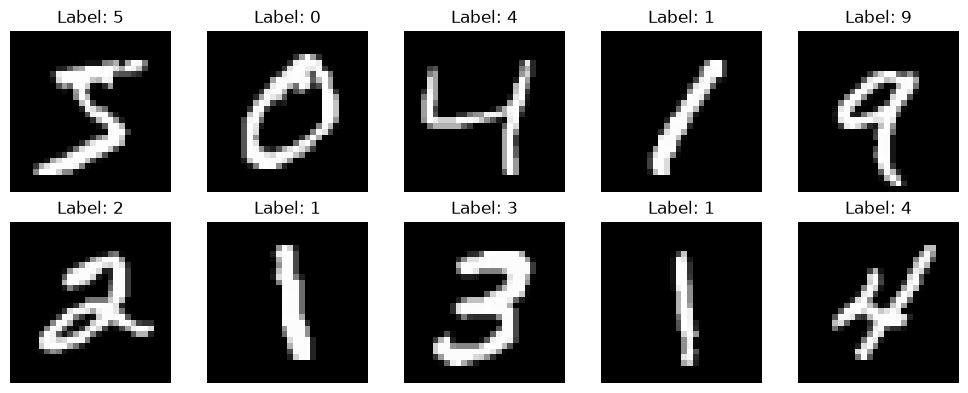

In [6]:
# ============================================================
# 4. Display some sample images
# ============================================================

plt.figure(figsize=(10, 4))
#first 10 images.
for i in range(10):
    plt.subplot(2, 5, i + 1) #2 rows and 5 columns
    plt.imshow(X[i].reshape(28, 28), cmap="gray") #each image currently has: 784 values and display it as a grayscale image
    plt.title(f"Label: {y[i]}") #Displaying the label as title
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# 5. Split data into training and testing sets
# ============================================================

# We use 50,000 images for training
# and 10,000 images for testing.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=50000,
    test_size=10000,
    random_state=42,
    stratify=y #makes sure the training and testing sets have approximately the same distribution of digits.
)

print("\nTraining data:", X_train.shape)
print("Testing data :", X_test.shape)


Training data: (50000, 784)
Testing data : (10000, 784)


In [8]:
# ============================================================
# 6. Nearest Neighbor (1-NN) Classifier
# ============================================================

print("\n==============================")
print("1-NN CLASSIFIER")
print("==============================")

start_time = time.time()

nn = KNeighborsClassifier(
    n_neighbors=1, #makes a 1-Nearest Neighbor classifier.
    metric="euclidean",
    n_jobs=-1 #ells Scikit-learn to use all available CPU cores where supported.
)

nn.fit(X_train, y_train)

#Measuring training time
training_time_nn = time.time() - start_time

# Prediction
start_time = time.time()

y_pred_nn = nn.predict(X_test)

prediction_time_nn = time.time() - start_time

# Accuracy
accuracy_nn = accuracy_score(y_test, y_pred_nn)

print("1-NN Accuracy:", accuracy_nn)
print("Training Time:", training_time_nn, "seconds")
print("Prediction Time:", prediction_time_nn, "seconds")

print("\nClassification Report - 1NN")
print(classification_report(y_test, y_pred_nn))


1-NN CLASSIFIER
1-NN Accuracy: 0.9699
Training Time: 0.014611244201660156 seconds
Prediction Time: 2.7940094470977783 seconds

Classification Report - 1NN
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       986
           1       0.97      0.99      0.98      1125
           2       0.98      0.96      0.97       998
           3       0.97      0.96      0.97      1020
           4       0.98      0.97      0.97       975
           5       0.96      0.96      0.96       902
           6       0.97      0.99      0.98       983
           7       0.96      0.98      0.97      1042
           8       0.98      0.94      0.96       975
           9       0.95      0.95      0.95       994

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [9]:
# ============================================================
# 7. KNN Classifier with different K values
# ============================================================

k_values = [3, 5, 7, 9]

accuracies = []
prediction_times = []

print("\n==============================")
print("KNN CLASSIFIER")
print("==============================")

for k in k_values:

    print(f"\nRunning KNN with K = {k}")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        n_jobs=-1
    )

    start_time = time.time()

    knn.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Prediction
    start_time = time.time()

    y_pred = knn.predict(X_test)

    prediction_time = time.time() - start_time

    accuracy = accuracy_score(y_test, y_pred)

    accuracies.append(accuracy)
    prediction_times.append(prediction_time)

    print("Accuracy:", accuracy)
    print("Training Time:", training_time, "seconds")
    print("Prediction Time:", prediction_time, "seconds")


KNN CLASSIFIER

Running KNN with K = 3
Accuracy: 0.9693
Training Time: 0.012788057327270508 seconds
Prediction Time: 2.8589823246002197 seconds

Running KNN with K = 5
Accuracy: 0.9697
Training Time: 0.018942594528198242 seconds
Prediction Time: 2.8756837844848633 seconds

Running KNN with K = 7
Accuracy: 0.9678
Training Time: 0.016907691955566406 seconds
Prediction Time: 2.8728442192077637 seconds

Running KNN with K = 9
Accuracy: 0.9658
Training Time: 0.01535940170288086 seconds
Prediction Time: 2.753455638885498 seconds


In [10]:
# ============================================================
# 8. Display Accuracy Results
# ============================================================

print("\n==============================")
print("ACCURACY COMPARISON")
print("==============================")

print(f"1-NN Accuracy: {accuracy_nn:.4f}")

for k, accuracy in zip(k_values, accuracies):
    print(f"KNN K={k} Accuracy: {accuracy:.4f}")


ACCURACY COMPARISON
1-NN Accuracy: 0.9699
KNN K=3 Accuracy: 0.9693
KNN K=5 Accuracy: 0.9697
KNN K=7 Accuracy: 0.9678
KNN K=9 Accuracy: 0.9658


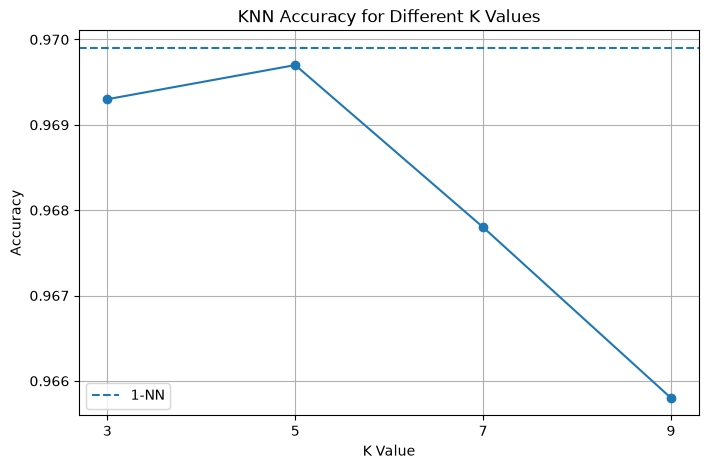

In [11]:
# ============================================================
# 9. Plot Accuracy vs K
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracies,
    marker="o"
)

plt.axhline(
    accuracy_nn,
    linestyle="--",
    label="1-NN"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.show()

In [12]:
# ============================================================
# 10. Find Best K
# ============================================================

best_index = np.argmax(accuracies)
best_k = k_values[best_index]
best_accuracy = accuracies[best_index]

print("\n==============================")
print("BEST K")
print("==============================")

print("Best K value:", best_k)
print("Best KNN accuracy:", best_accuracy)


BEST K
Best K value: 5
Best KNN accuracy: 0.9697


In [13]:
# ============================================================
# 11. Train final KNN using best K
# ============================================================

print("\nTraining final KNN model...")

best_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="euclidean",
    n_jobs=-1
)

best_knn.fit(X_train, y_train)

y_pred_best = best_knn.predict(X_test)


Training final KNN model...



FINAL KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       986
           1       0.96      0.99      0.97      1125
           2       0.98      0.96      0.97       998
           3       0.97      0.97      0.97      1020
           4       0.98      0.95      0.97       975
           5       0.96      0.96      0.96       902
           6       0.98      0.99      0.98       983
           7       0.96      0.98      0.97      1042
           8       0.98      0.94      0.96       975
           9       0.95      0.95      0.95       994

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



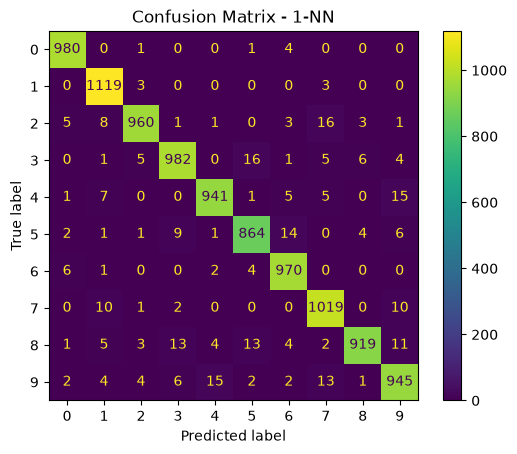

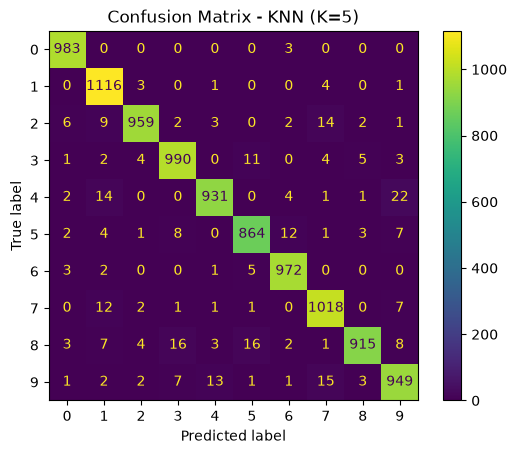

In [14]:
# ============================================================
# 12. Classification Report
# ============================================================

print("\n==============================")
print("FINAL KNN CLASSIFICATION REPORT")
print("==============================")

print(
    classification_report(
        y_test,
        y_pred_best
    )
)

# ============================================================
# 13. Confusion Matrix for 1-NN
# ============================================================

cm_nn = confusion_matrix(
    y_test,
    y_pred_nn
)

disp_nn = ConfusionMatrixDisplay(
    confusion_matrix=cm_nn
)

disp_nn.plot()

plt.title("Confusion Matrix - 1-NN")
plt.show()

# ============================================================
# 14. Confusion Matrix for Best KNN
# ============================================================

cm_knn = confusion_matrix(
    y_test,
    y_pred_best
)

disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn
)

disp_knn.plot()

plt.title(f"Confusion Matrix - KNN (K={best_k})")
plt.show()

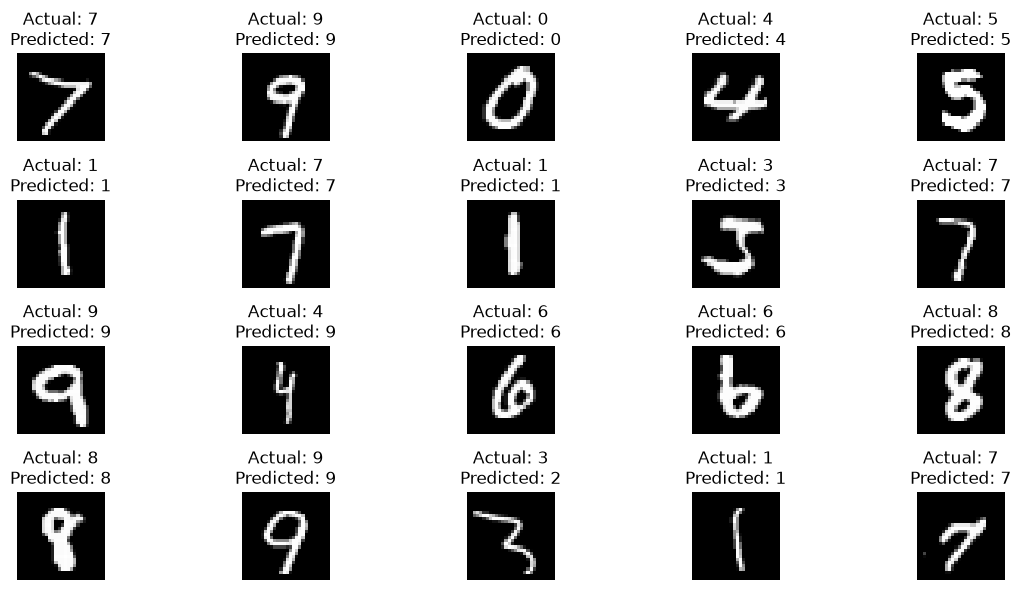

In [15]:
# ============================================================
# 15. Display Some Predictions
# ============================================================

plt.figure(figsize=(12, 6))

for i in range(20):

    plt.subplot(4, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred_best[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# 16. Final Comparison Table
# ============================================================

print("\n==============================")
print("FINAL RESULTS")
print("==============================")

print("\nModel              Accuracy")
print("--------------------------------")

print(
    f"1-NN               {accuracy_nn:.4f}"
)

for k, accuracy in zip(k_values, accuracies):

    print(
        f"KNN (K={k})          {accuracy:.4f}"
    )

print("\nBest K:", best_k)
print("Best Accuracy:", best_accuracy)


FINAL RESULTS

Model              Accuracy
--------------------------------
1-NN               0.9699
KNN (K=3)          0.9693
KNN (K=5)          0.9697
KNN (K=7)          0.9678
KNN (K=9)          0.9658

Best K: 5
Best Accuracy: 0.9697
